# Analysis

Robot beacon localization project — Step 5. Reuses `map_gen.py`, `visibility.py`, `solvers.py`.

The first four steps built the complete pipeline and used constraint generation to make the solutions reliable. This step uses it to answer four questions:

1. **How much more does requiring 3 visible beacons cost than requiring just 1?** — the cost of the project's core constraint
2. **Where do the optimal beacons go?** — testing the theoretical intuition that "reflex corners are optimal"
3. **Can the candidate set be trimmed?** — this directly affects problem size and solve speed
4. **Do the answers hold on a large sample, and what drives the number of beacons — map size or map complexity?** — using the 472 verified maps of the deep-learning dataset

All results are verified by constraint generation, not approximate coarse-grid answers: every solution is checked point by point on the fine grid and is optimal for the coarse and fine sample points together (see `refinement.ipynb`). The fine grid here is `RES_CHECK = 8` rather than the `RES = 16` of `refinement.ipynb`, to keep the many solves fast; the dataset in Question 4 uses the same setting.

In [1]:
import time
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

from map_gen import make_map
from visibility import sample_points, visibility_matrix, wall_arrays
from solvers import constraint_generation

GRID_W, GRID_H, TARGET, HOLES = 16, 12, 100, 8
RES_SOLVE, RES_CHECK = 4, 8
SEEDS = range(4)


def corner_kind(p, cells):
    """Whether lattice point p is a reflex corner / convex corner / other of the free space.
    Count the free cells in the 2x2 block around it: 3 -> reflex corner, 1 -> convex corner."""
    px, py = int(p[0]), int(p[1])
    quad = [(px - 1, py - 1), (px, py - 1), (px - 1, py), (px, py)]
    f = sum(c in cells for c in quad)
    return {1: 'convex', 3: 'reflex'}.get(f, 'other')


def build(seed):
    """Generate one map and all the data needed to solve it"""
    cells, segs, corners, mids = make_map(GRID_W, GRID_H, TARGET, HOLES, seed)
    W1, W2 = wall_arrays(segs)
    return {
        'cells': cells, 'segs': segs, 'corners': corners, 'mids': mids,
        'beacons': corners + mids, 'W1': W1, 'W2': W2,
        'P_solve': sample_points(cells, RES_SOLVE),
        'P_check': sample_points(cells, RES_CHECK),
    }


def solve(m, beacons=None, k=3):
    """Run constraint generation on the given candidate set; returns the selected indices"""
    B = m['beacons'] if beacons is None else beacons
    sol, _ = constraint_generation(B, m['cells'], m['W1'], m['W2'],
                                   m['P_solve'], m['P_check'], k=k)
    return sol


maps = {s: build(s) for s in SEEDS}
print(f'{len(maps)} maps, about {len(maps[0]["cells"])} cells each, '
      f'{len(maps[0]["beacons"])} candidate beacons')
print(f'solve grid RES={RES_SOLVE}, verification grid RES={RES_CHECK}')

4 maps, about 92 cells each, 132 candidate beacons
solve grid RES=4, verification grid RES=8


## Question 1: the cost of "seeing 3"

$k=1$ is the classic **art gallery problem** (every point is seen by at least one guard). Our problem is $k=3$.

Intuitively $k=3$ should cost **less than** 3 times as much — because beacons are shared: a beacon in an open area serves a large region at once,
and when $k$ increases those regions can reuse existing beacons. Is that what we actually measure?

In [2]:
t0 = time.time()
k_res = {}
sol_k3 = {}   # kept for reuse in Question 2, to avoid recomputing
for s, m in maps.items():
    k_res[s] = {}
    for k in (1, 2, 3):
        sol = solve(m, k=k)
        k_res[s][k] = len(sol)
        if k == 3:
            sol_k3[s] = sol

print(f'{"seed":>5} {"k=1":>5} {"k=2":>5} {"k=3":>5} | {"k2/k1":>6} {"k3/k1":>6}')
print('-' * 44)
for s in SEEDS:
    r = k_res[s]
    print(f'{s:>5} {r[1]:>5} {r[2]:>5} {r[3]:>5} | '
          f'{r[2] / r[1]:>6.2f} {r[3] / r[1]:>6.2f}')
print('-' * 44)
A = np.array([[k_res[s][k] for k in (1, 2, 3)] for s in SEEDS], dtype=float)
print(f'{"mean":>5} {A[:, 0].mean():>5.1f} {A[:, 1].mean():>5.1f} {A[:, 2].mean():>5.1f} | '
      f'{(A[:, 1] / A[:, 0]).mean():>6.2f} {(A[:, 2] / A[:, 0]).mean():>6.2f}')
print(f'\n({time.time() - t0:.0f}s)')

 seed   k=1   k=2   k=3 |  k2/k1  k3/k1
--------------------------------------------
    0     7    14    22 |   2.00   3.14
    1     7    15    22 |   2.14   3.14
    2     9    18    27 |   2.00   3.00
    3     7    15    23 |   2.14   3.29
--------------------------------------------
 mean   7.5  15.5  23.5 |   2.07   3.14

(22s)


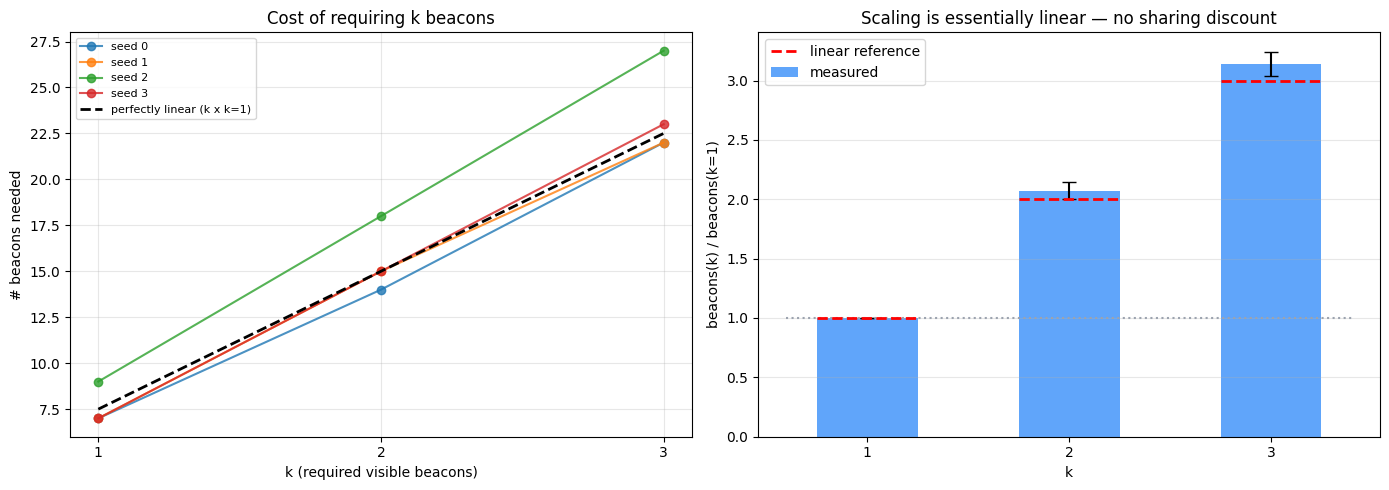

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, s in enumerate(SEEDS):
    axes[0].plot([1, 2, 3], A[i], 'o-', label=f'seed {s}', alpha=0.8)
axes[0].plot([1, 2, 3], [A[:, 0].mean() * k for k in (1, 2, 3)], 'k--',
             label='perfectly linear (k x k=1)', linewidth=2)
axes[0].set_xticks([1, 2, 3]); axes[0].set_xlabel('k (required visible beacons)')
axes[0].set_ylabel('# beacons needed'); axes[0].legend(fontsize=8)
axes[0].set_title('Cost of requiring k beacons'); axes[0].grid(alpha=0.3)

ratios = A / A[:, [0]]
axes[1].bar([1, 2, 3], ratios.mean(axis=0), 0.5, color='#60a5fa',
            yerr=ratios.std(axis=0), capsize=5, label='measured')
axes[1].plot([0.6, 3.4], [1, 1], ':', color='#9ca3af')
for k in (1, 2, 3):
    axes[1].plot([k - 0.25, k + 0.25], [k, k], 'r--', linewidth=2,
                 label='linear reference' if k == 1 else None)
axes[1].set_xticks([1, 2, 3]); axes[1].set_xlabel('k')
axes[1].set_ylabel('beacons(k) / beacons(k=1)')
axes[1].set_title('Scaling is essentially linear — no sharing discount')
axes[1].legend(); axes[1].grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()

**Conclusion (counter-intuitive)**: the cost is almost **exactly linear** — $k=3$ needs about 3 times as many beacons as $k=1$, or even slightly more. The sharing dividend does not materialize.

The reason is that **the bottleneck is not the open areas but the dead corners**. Open areas can indeed share beacons, but the total is determined by positions
tucked into narrow reflex corners that can only see a few walls to begin with. For such a position to be seen 3 times it needs 3
dedicated beacons, with no room for reuse. As $k$ grows, the demand of these bottleneck points grows linearly, so the total grows linearly too.

It is slightly **more** than 3 times because with $k=1$ the solver can pick only the "hub" positions with the best views; $k=3$ needs more beacons,
and once the good positions are used up, candidates with poorer views have to be used.

## Question 2: where do the optimal beacons go

The candidate set contains three kinds of positions: **reflex corners** (the wall turns inward), **convex corners** (the wall turns outward), and **wall-segment midpoints**.
Art gallery theory predicts that reflex corners are the key positions — reflex corners are exactly what blocks lines of sight, and a beacon there can see both of the regions they separate.

We test this by computing the **selection rate** (number selected / number available) of each kind of candidate.

Two caveats: a map usually has many optimal layouts, and CP-SAT (with 8 workers) returns one of them non-deterministically, so the rates move a little from run to run — the ranking does not; and "midpoint" here also includes pinch points, which Question 4 separates out.

candidate type      chosen  avail     rate
------------------------------------------
corner-reflex           56    160    35.0%
midpoint                30    266    11.3%
corner-convex            8    106     7.5%
------------------------------------------
total                   94    532


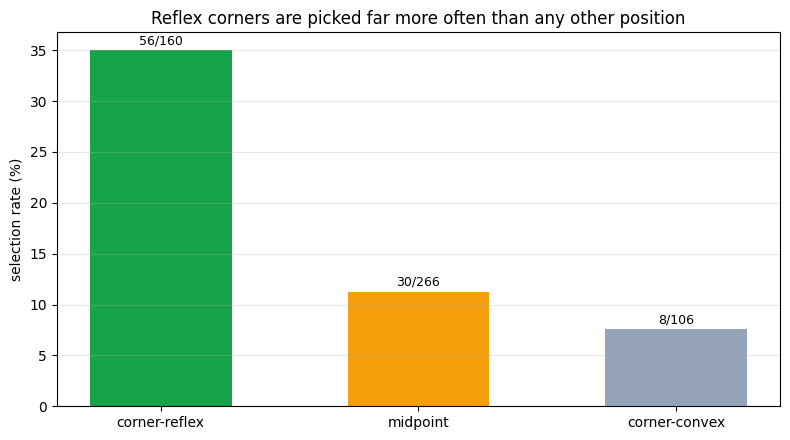

In [4]:
chosen_ct, avail_ct = Counter(), Counter()
for s, m in maps.items():
    n_cor = len(m['corners'])
    sel = set(sol_k3[s])                       # reuse the k=3 solutions from Question 1
    for j, p in enumerate(m['beacons']):
        kind = ('midpoint' if j >= n_cor
                else f'corner-{corner_kind(p, m["cells"])}')
        avail_ct[kind] += 1
        if j in sel:
            chosen_ct[kind] += 1

kinds = sorted(avail_ct, key=lambda x: -chosen_ct[x] / avail_ct[x])
print(f'{"candidate type":<18} {"chosen":>7} {"avail":>6} {"rate":>8}')
print('-' * 42)
for kd in kinds:
    print(f'{kd:<18} {chosen_ct[kd]:>7} {avail_ct[kd]:>6} '
          f'{100 * chosen_ct[kd] / avail_ct[kd]:>7.1f}%')
print('-' * 42)
print(f'{"total":<18} {sum(chosen_ct.values()):>7} {sum(avail_ct.values()):>6}')

fig, ax = plt.subplots(figsize=(8, 4.5))
rates = [100 * chosen_ct[kd] / avail_ct[kd] for kd in kinds]
bars = ax.bar(kinds, rates, 0.55,
              color=['#16a34a', '#f59e0b', '#94a3b8'][:len(kinds)])
for b, kd in zip(bars, kinds):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.6,
            f'{chosen_ct[kd]}/{avail_ct[kd]}', ha='center', fontsize=9)
ax.set_ylabel('selection rate (%)')
ax.set_title('Reflex corners are picked far more often than any other position')
ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()

## Question 3: can the candidate set be trimmed

Since reflex corners are clearly more useful, a natural idea is to drop the other candidates to shrink the problem. We test three candidate sets:

- **All** (corners + wall-segment midpoints)
- **Corners only** (midpoints removed, half the size)
- **Reflex corners only** (keep only the theoretically optimal positions)

Note that a trimmed candidate set can make the problem **infeasible** — if some position cannot see 3 beacons at all under the reduced candidate set.

In [5]:
def feasible(m, B, k=3):
    """Using all the given candidates, can every point on the fine grid see k of them"""
    Vf = visibility_matrix(B, m['P_check'], m['cells'], m['W1'], m['W2'])
    return not bool((Vf.sum(axis=1) < k).any())


print(f'{"seed":>5} | {"all candidates":>16} | {"corners only":>16} | {"reflex only":>16}')
print(f'{"":>5} | {"M":>4} {"n":>4} {"t":>6} | {"M":>4} {"n":>4} {"t":>5} | '
      f'{"M":>4} {"n":>4} {"t":>5}')
print('-' * 62)
abl = []
for s, m in maps.items():
    reflex = [p for p in m['corners'] if corner_kind(p, m['cells']) == 'reflex']
    row = []
    for name, B in [('all', m['beacons']), ('corners', m['corners']),
                    ('reflex', reflex)]:
        if name == 'all':
            row.append((len(B), len(sol_k3[s]), 0.0))     # reused
            continue
        if not feasible(m, B):
            row.append((len(B), None, 0.0))               # infeasible with this candidate set
            continue
        t0 = time.time()
        row.append((len(B), len(solve(m, beacons=B)), time.time() - t0))
    abl.append({'seed': s, 'row': row})
    f = lambda t: f'{t[0]:>4} {"—" if t[1] is None else t[1]:>4} {t[2]:>5.1f}s'
    print(f'{s:>5} | {f(row[0]):>16} | {f(row[1]):>16} | {f(row[2]):>16}')
print('-' * 62)
print('n = "—" means no feasible solution with this candidate set')

d = [r['row'][1][1] - r['row'][0][1] for r in abl if r['row'][1][1] is not None]
if d:
    print(f'\nDropping wall midpoints costs {np.mean(d):.1f} extra beacons on average '
          f'({100 * np.mean(d) / np.mean([r["row"][0][1] for r in abl]):.0f}%),'
          f' but halves the candidate set')

 seed |   all candidates |     corners only |      reflex only
      |    M    n      t |    M    n     t |    M    n     t
--------------------------------------------------------------
    0 |  132   22   0.0s |   66   23   1.2s |   40    —   0.0s
    1 |  124   22   0.0s |   62   24   1.1s |   37    —   0.0s
    2 |  144   27   0.0s |   72   33   0.9s |   46    —   0.0s
    3 |  132   23   0.0s |   66   26   1.8s |   37    —   0.0s
--------------------------------------------------------------
n = "—" means no feasible solution with this candidate set

Dropping wall midpoints costs 3.0 extra beacons on average (13%), but halves the candidate set


## Question 4: a larger sample — 472 verified maps

Questions 1–3 rest on 4 maps. The deep-learning dataset (`dl_data.npz`, built by `dl_dataset.py`) has 472 random maps, each with an optimal layout
verified by constraint generation (`RES` 4 → 8), and with its area and number of holes drawn independently. That is enough to re-check Question 2
on a large sample and to ask one more question: **what drives the number of beacons — map size or map complexity?**

Position types come from `map_gen.cand_kind`, which also separates **pinch points** from the other midpoints: lattice points where two free cells
touch only diagonally. A pinch point lies in the middle of two crossing wall segments, so it enters the candidate set only when it happens to be
one of their midpoints — and a beacon there is visible from both free cells.

472 maps, 63568 candidates, 11717 optimal beacons

candidate type      chosen  avail     rate   share
--------------------------------------------------
pinch                  860   1459    58.9%    7.3%
reflex                7437  18894    39.4%   63.5%
midpoint              2583  30057     8.6%   22.0%
convex                 837  13158     6.4%    7.1%
share = fraction of all optimal beacons

pinch points that are candidates: 1459 of 1866


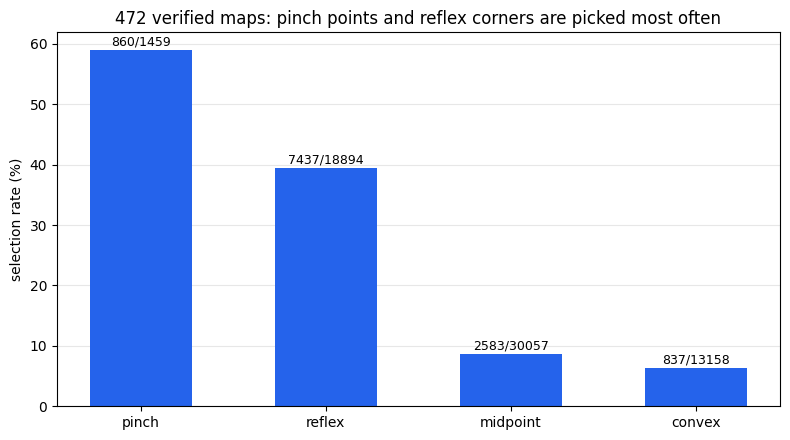

In [6]:
import dl_dataset as dd
from map_gen import cand_kind

data = np.load('dl_data.npz')        # 472 maps with verified optimal layouts, built by dl_dataset.py
rows = []                            # one entry per map
for i, seed in enumerate(int(s) for s in data['seed']):
    cells, segs, corners, mids = make_map(dd.GRID_W, dd.GRID_H, *dd.map_params(seed), seed)
    cands = dd.unique_candidates(corners, mids)
    kinds = [cand_kind(p, cells) for p in cands]
    lattice = [(x, y) for x in range(dd.GRID_W + 1) for y in range(dd.GRID_H + 1)]
    rows.append({'area': len(cells), 'reflex': kinds.count('reflex'), 'n_opt': int(data['n_beacons'][i]),
                 'kinds': kinds, 'chosen': [data['Y'][i][dd.to_raster_index(p)] > 0.5 for p in cands],
                 'pinch_all': sum(cand_kind(p, cells) == 'pinch' for p in lattice)})

avail, chosen = Counter(), Counter()
for r in rows:
    avail.update(r['kinds'])
    chosen.update(k for k, c in zip(r['kinds'], r['chosen']) if c)
n_sel = sum(chosen.values())
kinds = sorted(avail, key=lambda k: -chosen[k] / avail[k])

print(f'{len(rows)} maps, {sum(avail.values())} candidates, {n_sel} optimal beacons\n')
print(f'{"candidate type":<18} {"chosen":>7} {"avail":>6} {"rate":>8} {"share":>7}')
print('-' * 50)
for kd in kinds:
    print(f'{kd:<18} {chosen[kd]:>7} {avail[kd]:>6} {100 * chosen[kd] / avail[kd]:>7.1f}% '
          f'{100 * chosen[kd] / n_sel:>6.1f}%')
print('share = fraction of all optimal beacons')
print(f'\npinch points that are candidates: {avail["pinch"]} of {sum(r["pinch_all"] for r in rows)}')

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(kinds, [100 * chosen[kd] / avail[kd] for kd in kinds], 0.55, color='#2563eb')
for b, kd in zip(bars, kinds):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.8,
            f'{chosen[kd]}/{avail[kd]}', ha='center', fontsize=9)
ax.set_ylabel('selection rate (%)')
ax.set_title(f'{len(rows)} verified maps: pinch points and reflex corners are picked most often')
ax.grid(alpha=0.3, axis='y'); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

correlation with the optimal number of beacons:  area r = +0.03,  reflex corners r = +0.58
(area and reflex corners are themselves correlated: r = +0.58)
least squares: beacons ≈ -0.112 × area +0.522 × reflex corners +13.5


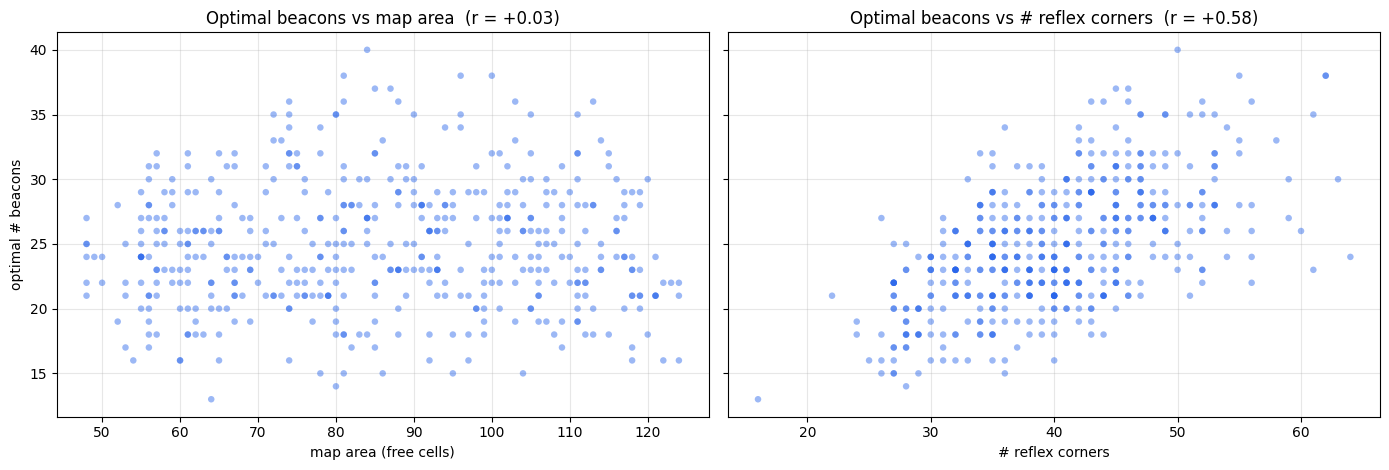

In [7]:
area = np.array([r['area'] for r in rows])
refl = np.array([r['reflex'] for r in rows])
n_opt = np.array([r['n_opt'] for r in rows])
r_area, r_refl = np.corrcoef(area, n_opt)[0, 1], np.corrcoef(refl, n_opt)[0, 1]
coef = np.linalg.lstsq(np.column_stack([area, refl, np.ones(len(rows))]), n_opt, rcond=None)[0]

print(f'correlation with the optimal number of beacons:  area r = {r_area:+.2f},  reflex corners r = {r_refl:+.2f}')
print(f'(area and reflex corners are themselves correlated: r = {np.corrcoef(area, refl)[0, 1]:+.2f})')
print(f'least squares: beacons ≈ {coef[0]:+.3f} × area {coef[1]:+.3f} × reflex corners {coef[2]:+.1f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, x, name, r in [(axes[0], area, 'map area (free cells)', r_area),
                       (axes[1], refl, '# reflex corners', r_refl)]:
    ax.scatter(x, n_opt, s=22, color='#2563eb', alpha=0.45, edgecolor='none')
    ax.set_xlabel(name)
    ax.set_title(f'Optimal beacons vs {name.split(" (")[0]}  (r = {r:+.2f})')
    ax.grid(alpha=0.3); ax.set_axisbelow(True)
axes[0].set_ylabel('optimal # beacons')
plt.tight_layout(); plt.show()

**What the large sample shows.** The ranking of Question 2 holds, with one addition: **pinch points are the best positions of all** —
picked about 59% of the time, against about 39% for reflex corners and under 10% for midpoints and convex corners. Reflex corners still host
most beacons (about 64%) simply because there are far more of them; pinch points are rare (about 2% of candidates), and only 78% of them are
candidates at all, because a pinch point enters the candidate set only when it happens to be a segment midpoint.

**Size vs complexity.** The optimal count is essentially uncorrelated with the area (r = 0.03) but clearly correlated with the number of reflex
corners (r = 0.58). Holding reflex corners fixed, extra area even slightly *reduces* the count (more open space per corner). The rising trend
with area in `optimization.ipynb` came from its experiment design, where the number of holes grew together with the area.

## Four conclusions

**1. The cost of "seeing 3" is linear, with no discount.** $k=3$ needs about 3 times as many beacons as $k=1$, or even slightly more.
This means the localization requirement (as opposed to merely "being seen") is a **genuine threefold cost**; sharing cannot be counted on to save anything.
The root cause is narrow dead corners: there is no room for reuse there. If cost matters in a real deployment, the better lever is **reshaping the map**
(fewer dead corners) rather than optimizing the algorithm.

**2. Reflex corners are indeed key positions — pinch points even more so — but they are not enough.** Reflex corners are selected far more often than convex corners and wall-segment midpoints, consistent with art gallery theory; the 472-map sample of Question 4 confirms this and finds an even better position, the diagonal pinch point, which sees two regions at once.
But using only reflex corners makes the problem **infeasible** — some positions cannot see 3 beacons when only reflex-corner beacons exist. So the theoretical intuition points in the right direction,
but cannot be the entire candidate set. Since pinch points enter the candidate set only when they happen to be a segment midpoint,
**adding every pinch point as a candidate** is a cheap improvement worth testing.

**3. Wall-segment midpoints are worth keeping.** Removing them halves the candidate set and speeds up solving, at the cost of about 13% more beacons (3.0 more per map on average, 23.5 → 26.5).
If the goal is to minimize the number of beacons (this project's goal), keep them; for very large maps where speed comes first,
dropping the midpoints is a reasonable trade-off.

**4. Complexity, not size, drives the cost.** Across 472 verified maps the optimal number of beacons is essentially unrelated to map area
(r = 0.03) but grows with the number of reflex corners (r = 0.58). To save beacons, remove dead corners rather than shrink the map —
the same lever as in conclusion 1.

**A methodological caveat**: all conclusions above rest on solutions verified by constraint generation. Doing the same analysis directly on coarse-grid answers
would distort the comparison itself, because the amount of underestimation is not consistent across different $k$ and different candidate sets (see `refinement.ipynb`).